In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/formated/MedicalStudent_MentalHealth_Cleaned.csv')

In [4]:
df.sample(10)

,student_id,age,curriculum_year,gender,native_language,has_partner,has_job,weekly_study_hours,health_satisfaction,health_satisfaction_score,...,qcae_cognitive_empathy,qcae_affective_empathy,amsp_meaning_in_patient_care,gert_emotion_recognition_rate,cesd_depression_score,stai_trait_anxiety_score,mbi_burnout_emotional_exhaustion,mbi_burnout_cynicism,mbi_burnout_academic_efficacy,cesd_depression_risk
396,783,22,Master 2 (Mmed2),Female,French,Yes,Yes,35,Satisfied,4,...,56,36,21,0.8333,13,31,10,9,28,Normal (<16)
362,726,24,Bachelor 1 (Bmed1),Female,French,Yes,No,9,Dissatisfied,2,...,56,34,18,0.6667,33,54,7,6,28,High Risk (>=16)
814,1643,21,Bachelor 1 (Bmed1),Female,French,Yes,No,40,Dissatisfied,2,...,62,46,28,0.8810,30,71,18,4,31,High Risk (>=16)
807,1633,18,Bachelor 1 (Bmed1),Female,French,No,No,42,Very satisfied,5,...,48,34,22,0.8095,9,31,17,5,28,Normal (<16)
513,1017,20,Bachelor 2 (Bmed2),Female,French,Yes,No,18,Neither satisfied nor dissatisfied,3,...,60,38,19,0.8571,10,40,12,5,31,Normal (<16)
141,283,20,Bachelor 2 (Bmed2),Female,French,No,Yes,26,Satisfied,4,...,63,42,17,0.7143,13,42,14,7,24,Normal (<16)
803,1625,23,Master 1 (Mmed1),Female,Portuguese,Yes,Yes,28,Satisfied,4,...,52,28,21,0.8095,21,44,22,15,17,High Risk (>=16)
621,1258,23,Bachelor 2 (Bmed2),Female,French,Yes,No,35,Satisfied,4,...,65,36,26,0.6190,34,35,24,13,22,High Risk (>=16)
28,64,19,Bachelor 1 (Bmed1),Female,Portuguese,Yes,No,15,Neither satisfied nor dissatisfied,3,...,64,46,25,0.7857,54,72,30,23,16,High Risk (>=16)
798,1613,29,Master 3 (Mmed3),Male,German,Yes,Yes,6,Very satisfied,5,...,54,30,24,0.7381,15,42,10,8,29,Normal (<16)


In [5]:
# calculate and count % of High risk vs normal 
risk_count = df['cesd_depression_risk'].value_counts()
print("Risk Count:\n", risk_count, "\n")
risk_percent = df['cesd_depression_risk'].value_counts(normalize=True) * 100
print("Risk Percent:\n", risk_percent)

Risk Count:
 cesd_depression_risk
High Risk (>=16)    461
Normal (<16)        425
Name: count, dtype: int64 

Risk Percent:
 cesd_depression_risk
High Risk (>=16)    52.031603
Normal (<16)        47.968397
Name: proportion, dtype: float64


In [6]:
df['cesd_depression_score'].describe()

count    886.000000
mean      18.050790
std       11.478731
min        0.000000
25%        9.000000
50%       16.000000
75%       25.000000
max       56.000000
Name: cesd_depression_score, dtype: float64

Text(0, 0.5, 'Count of Students by Depression Risk')

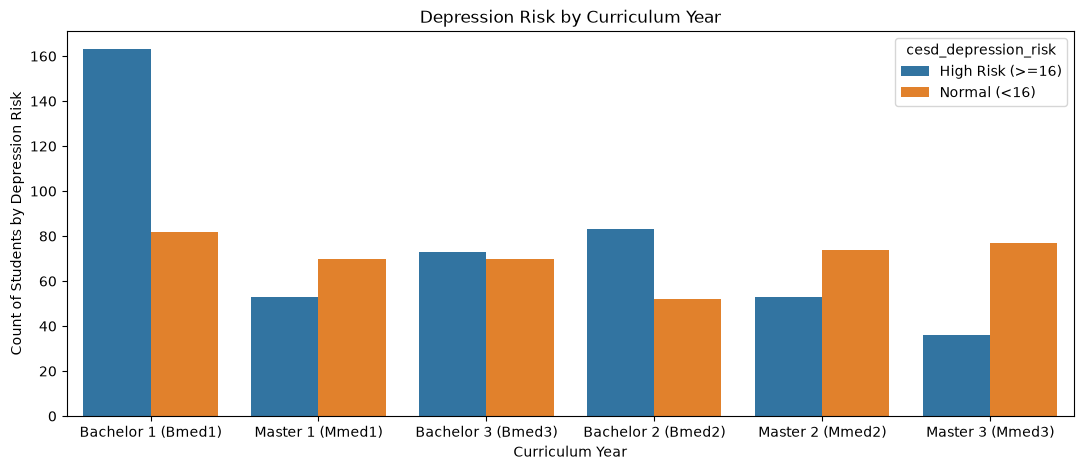

In [7]:
plt.figure(figsize=(13, 5))
sns.countplot(data=df, x='curriculum_year', hue='cesd_depression_risk')
plt.title('Depression Risk by Curriculum Year')
plt.xlabel('Curriculum Year')
plt.ylabel('Count of Students by Depression Risk')

Text(0, 0.5, 'Count of Students by Depression Risk')

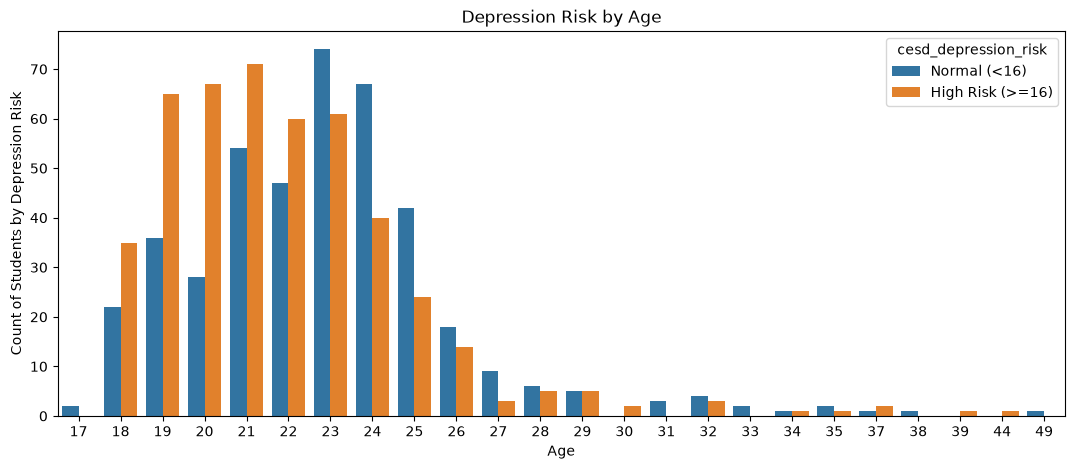

In [8]:
plt.figure(figsize=(13, 5))
sns.countplot(data=df, x='age', hue='cesd_depression_risk')
plt.title('Depression Risk by Age')
plt.xlabel('Age')
plt.ylabel('Count of Students by Depression Risk')

Text(0, 0.5, 'Count of Students by Depression Risk')

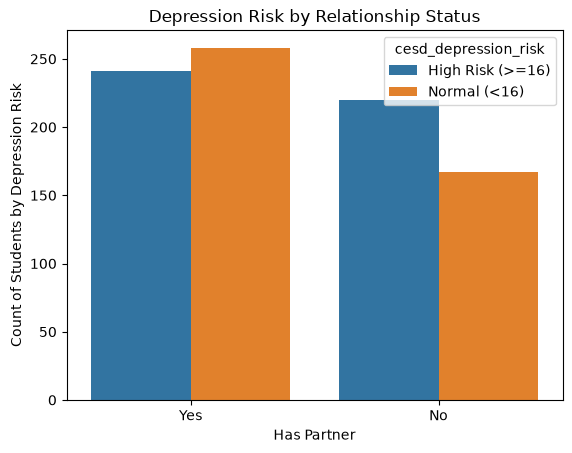

In [9]:
sns.countplot(data=df, x='has_partner', hue='cesd_depression_risk')
plt.title('Depression Risk by Relationship Status')
plt.xlabel('Has Partner')
plt.ylabel('Count of Students by Depression Risk')

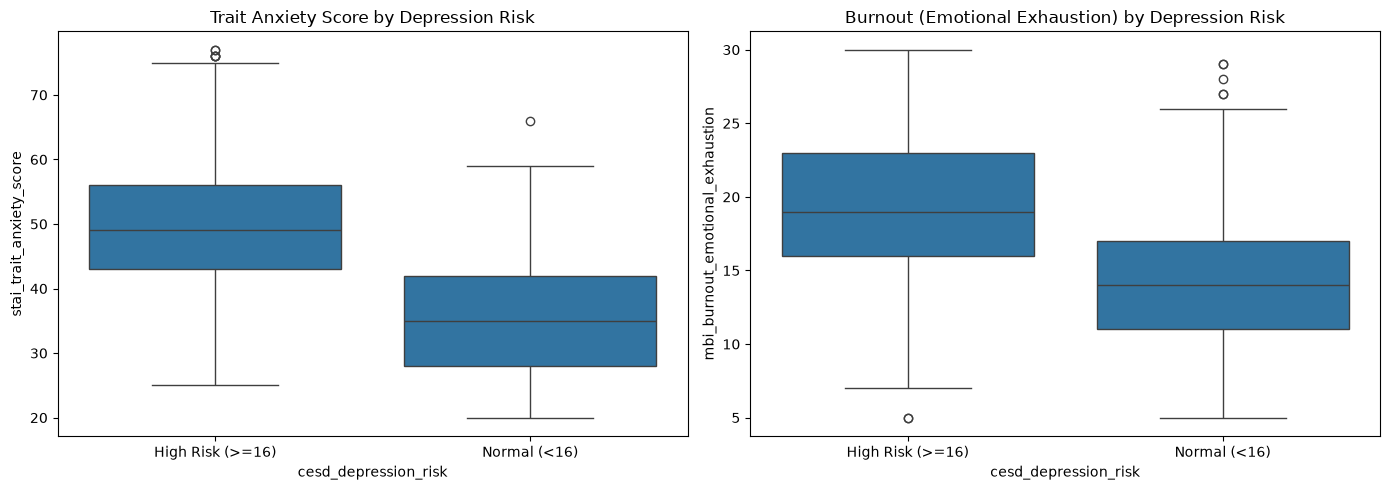

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Plot 1: Trait Anxiety vs Depression Risk
sns.boxplot(data=df, x='cesd_depression_risk', y='stai_trait_anxiety_score', ax=axes[0])
axes[0].set_title('Trait Anxiety Score by Depression Risk')

# Plot 2: Burnout (Emotional Exhaustion) vs Depression Risk
sns.boxplot(data=df, x='cesd_depression_risk', y='mbi_burnout_emotional_exhaustion', ax=axes[1])
axes[1].set_title('Burnout (Emotional Exhaustion) by Depression Risk')

plt.tight_layout()

Text(0.5, 1.0, 'Distribution of CESD Depression Scores by Risk Category')

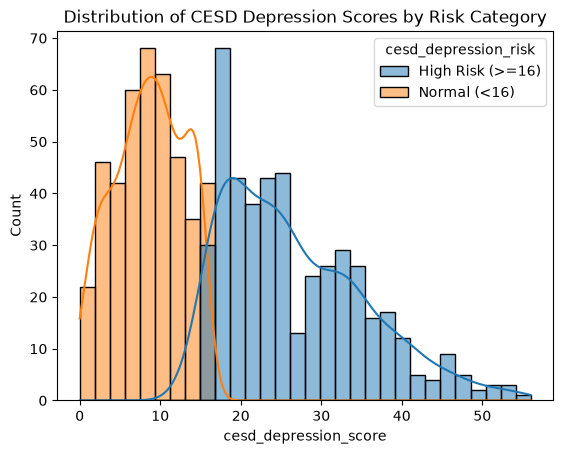

In [11]:
sns.histplot(data=df, x='cesd_depression_score', hue='cesd_depression_risk', bins=30, kde=True)
plt.title('Distribution of CESD Depression Scores by Risk Category')

<Axes: >

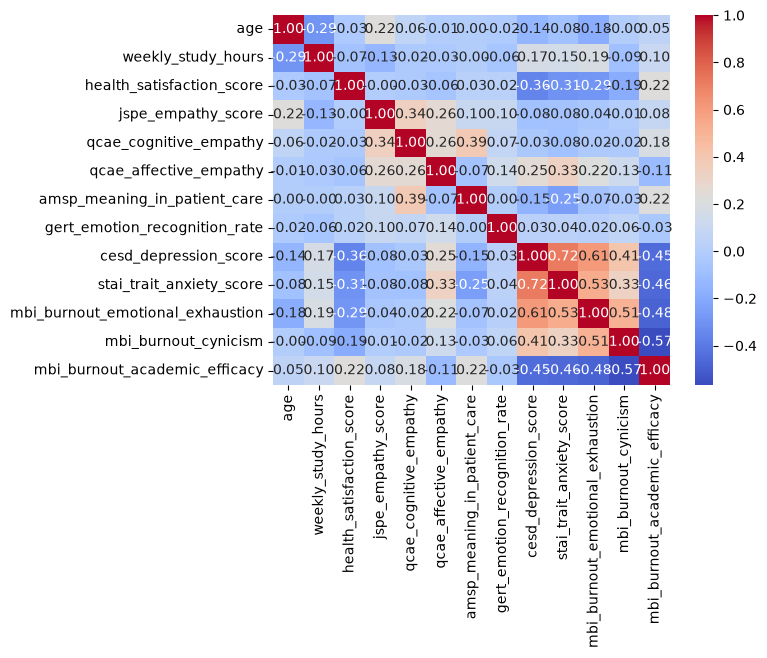

In [12]:
num_cols = df.select_dtypes(include=['int64', 'float64']).drop(columns=['student_id'])
corr_matrix = num_cols.corr()
# plt.figure(figsize=(13, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)

Text(0.5, 1.0, 'Correlation Matrix of Psychometric and Academic Scores')

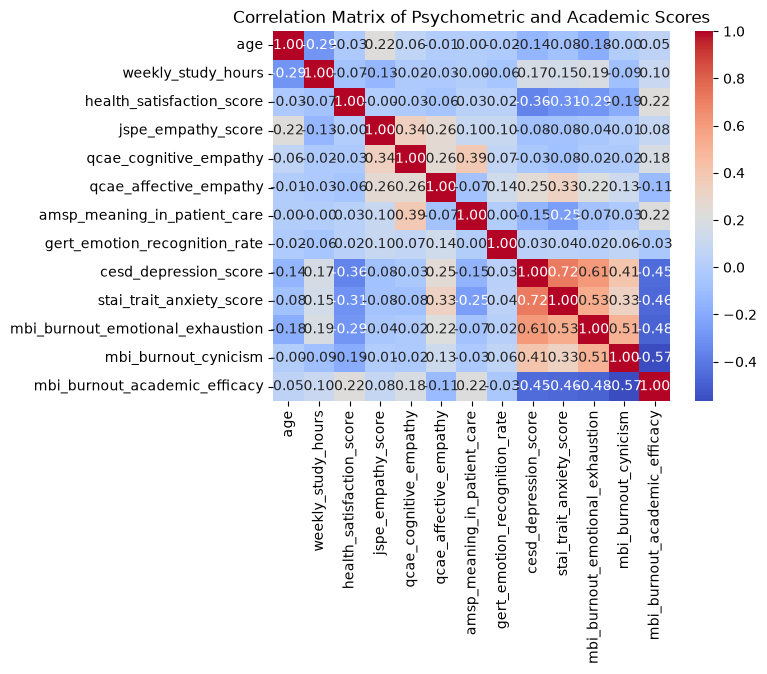

In [13]:
num_cols = df.select_dtypes(include=['int64', 'float64']).drop(columns=['student_id'])
corr_matrix = num_cols.corr()
# plt.figure(figsize=(13, 10))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Matrix of Psychometric and Academic Scores')